# 04 · Modelo de Regresión Logística: probabilidad de defunción por dengue

**Proyecto final · Análisis Estadístico Multivariado**

**Entrada:** `datos-procesados/dengue_limpio.csv` (generado en `02_limpieza.ipynb` y explorado en `03_EDA.ipynb`).

**Objetivo:** estimar la probabilidad de que un paciente con dengue confirmado fallezca,

$$p = P(\text{DEFUNCION} = 1 \mid X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

e interpretar el efecto de cada variable mediante su *odds ratio* $e^{\beta_j}$.

**Decisiones que vienen del EDA**

| Hallazgo del EDA | Decisión en este notebook |
|---|---|
| Solo 0.70 % de fallecidos | Partición estratificada; se evalúa con recall, precision, F1 y ROC-AUC además de accuracy |
| La edad no es lineal en el log-odds (forma de "U") | Se agrega el término `EDAD_ANOS_2` (edad²) |
| `HOSPITALIZADO` refleja la gravedad del paciente | Se compara el modelo final con y sin esta variable |
| Muchas variables con asociación débil | Selección de variables con *backward selection* (p-value, AIC y BIC) |

**Contenido**

1. Preparación de los datos
2. División en entrenamiento y prueba
3. Modelo completo
4. Selección de variables (*backward selection*)
5. Modelo final: interpretación de coeficientes y *odds ratios*
6. Análisis de la variable `HOSPITALIZADO`
7. Separabilidad de las probabilidades estimadas
8. Métricas de desempeño
9. Importancia de variables con SHAP
10. Probabilidad de puntos críticos
11. Conclusiones

## 1. Preparación de los datos

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from scipy.stats import gaussian_kde
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
import warnings
warnings.filterwarnings('ignore')
import shap
warnings.filterwarnings('ignore')

# Cargar datos
dengue = pd.read_csv('datos-procesados/dengue_limpio.csv')
print('Dimensiones:', dengue.shape)
print(f"Tasa de mortalidad: {dengue['DEFUNCION'].mean() * 100:.2f} %")

Dimensiones: (251900, 29)
Tasa de mortalidad: 0.70 %


En el EDA se observó que la mortalidad tiene forma de "U" con respecto a la edad. Para que el modelo pueda capturar esa curvatura se agrega la variable **edad al cuadrado**. Con los dos términos, el log-odds de la edad es una parábola: $\beta_1 \cdot edad + \beta_2 \cdot edad^2$.

In [2]:
# Término cuadrático de la edad
dengue['EDAD_ANOS_2'] = dengue['EDAD_ANOS'] ** 2

# Variables independientes (X) y dependiente (y)
X = dengue.drop(columns=['ID_REGISTRO', 'DEFUNCION'])
y = dengue['DEFUNCION']
print('Variables independientes:', X.shape[1])
print(list(X.columns))

Variables independientes: 28
['HOMBRE', 'EDAD_ANOS', 'COSTERA', 'INDIGENA', 'HEMORRAGICOS', 'DIABETES', 'HIPERTENSION', 'ENFERMEDAD_RENAL', 'INMUNOSUPR', 'CIRROSIS_HEPATICA', 'EMBARAZO', 'HOSPITALIZADO', 'DENV2', 'DENV3', 'DENV4', 'SIN_SEROTIPO', 'MES_ENE', 'MES_FEB', 'MES_MAR', 'MES_ABR', 'MES_MAY', 'MES_JUN', 'MES_JUL', 'MES_AGO', 'MES_SEP', 'MES_NOV', 'MES_DIC', 'EDAD_ANOS_2']


## 2. División en entrenamiento y prueba

Si el modelo se evaluara con los mismos datos con los que se ajustó, las métricas serían optimistas: el modelo podría estar memorizando los datos (*overfitting*) en lugar de aprender patrones generales. Por eso se separa un **conjunto de prueba** que el modelo nunca ve durante el ajuste ni durante la selección de variables, y que solo se usa al final para medir su desempeño en datos nuevos.

- **70 % entrenamiento / 30 % prueba.**
- **Estratificado por `DEFUNCION`** (`stratify=y`): con un evento tan raro, una partición aleatoria simple podría dejar proporciones distintas de fallecidos en cada conjunto.
- `random_state=42` para que el resultado sea reproducible.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

pd.DataFrame({
    'Casos': [len(y_train), len(y_test)],
    'Fallecidos': [y_train.sum(), y_test.sum()],
    'Mortalidad (%)': [y_train.mean() * 100, y_test.mean() * 100],
}, index=['Entrenamiento', 'Prueba']).round(3)

,Casos,Fallecidos,Mortalidad (%)
Entrenamiento,176330,1234,0.7
Prueba,75570,529,0.7


Ambos conjuntos conservan la misma tasa de mortalidad (0.70 %), así que la estratificación funcionó.

## 3. Modelo completo

Se ajusta primero una regresión logística con **todas** las variables, usando `statsmodels` sobre el conjunto de entrenamiento.

In [4]:
modelo_completo = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)
print(modelo_completo.summary())

                           Logit Regression Results                           
Dep. Variable:              DEFUNCION   No. Observations:               176330
Model:                          Logit   Df Residuals:                   176301
Method:                           MLE   Df Model:                           28
Date:                Sat, 21 Nov 2026   Pseudo R-squ.:                  0.1742
Time:                        13:24:03   Log-Likelihood:                -6071.7
converged:                       True   LL-Null:                       -7352.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -8.1345      0.255    -31.876      0.000      -8.635      -7.634
HOMBRE                0.0604      0.059      1.017      0.309      -0.056       0.177
EDAD_ANOS            -0.

**Lectura de los estadísticos del modelo:**

- **Log-Likelihood (−6,071.7) vs. LL-Null (−7,352.9):** el modelo con predictores tiene una log-verosimilitud mucho mayor que el modelo sin predictores (que solo predice la tasa promedio de mortalidad), es decir, las variables sí aportan información.
- **LLR p-value ≈ 0:** la prueba de razón de verosimilitudes rechaza que todos los coeficientes sean cero. El modelo en conjunto es significativo.
- **Pseudo R² = 0.174:** el modelo mejora en 17.4 % la log-verosimilitud del modelo nulo. En regresión logística, valores de 0.2 a 0.4 se consideran un buen ajuste, por lo que el ajuste es moderado.
- **Coeficientes:** varias variables **no son significativas** (p-value > 0.05): sexo, entidad costera, indígena, hipertensión, embarazo, los cuatro serotipos y la mayoría de los meses. Esto justifica simplificar el modelo con *backward selection*.

## 4. Selección de variables: *backward selection*

Procedimiento:

1. Ajustar el modelo con todas las variables.
2. Identificar la variable con el **p-value más alto**.
3. Si ese p-value es mayor que el nivel de significancia ($\alpha = 0.05$), eliminar la variable y volver a ajustar el modelo.
4. Repetir hasta que todas las variables sean significativas.

En cada paso se registran el **AIC** y el **BIC** (criterios de información: penalizan la complejidad del modelo; **menor es mejor**). El BIC penaliza más el número de variables que el AIC.

In [5]:
alpha = 0.05
variables = list(X_train.columns)
pasos = []

while True:
    modelo = sm.Logit(y_train, sm.add_constant(X_train[variables])).fit(disp=0)
    p_values = modelo.pvalues.drop('const')
    peor = p_values.idxmax()
    pasos.append({'Núm. variables': len(variables), 'AIC': modelo.aic, 'BIC': modelo.bic,
                  'Variable con mayor p-value': peor, 'p-value': p_values.max()})
    if p_values.max() <= alpha:     # todas son significativas: se detiene
        break
    variables.remove(peor)          # se elimina la menos significativa

pasos = pd.DataFrame(pasos)
pasos['Acción'] = np.where(pasos['p-value'] > alpha, 'Se elimina', 'Se detiene (todas significativas)')
pasos.round(3)

,Núm. variables,AIC,BIC,Variable con mayor p-value,p-value,Acción
0,28,12201.452,12493.775,EMBARAZO,0.827,Se elimina
1,27,12199.501,12481.744,MES_NOV,0.827,Se elimina
2,26,12197.549,12469.712,MES_FEB,0.736,Se elimina
3,25,12195.661,12457.744,MES_ENE,0.636,Se elimina
4,24,12193.881,12445.884,MES_MAR,0.582,Se elimina
5,23,12192.195,12434.118,MES_AGO,0.499,Se elimina
6,22,12190.647,12422.490,MES_SEP,0.542,Se elimina
7,21,12189.017,12410.779,COSTERA,0.358,Se elimina
8,20,12187.870,12399.552,HOMBRE,0.285,Se elimina
9,19,12187.010,12388.612,DENV3,0.216,Se elimina


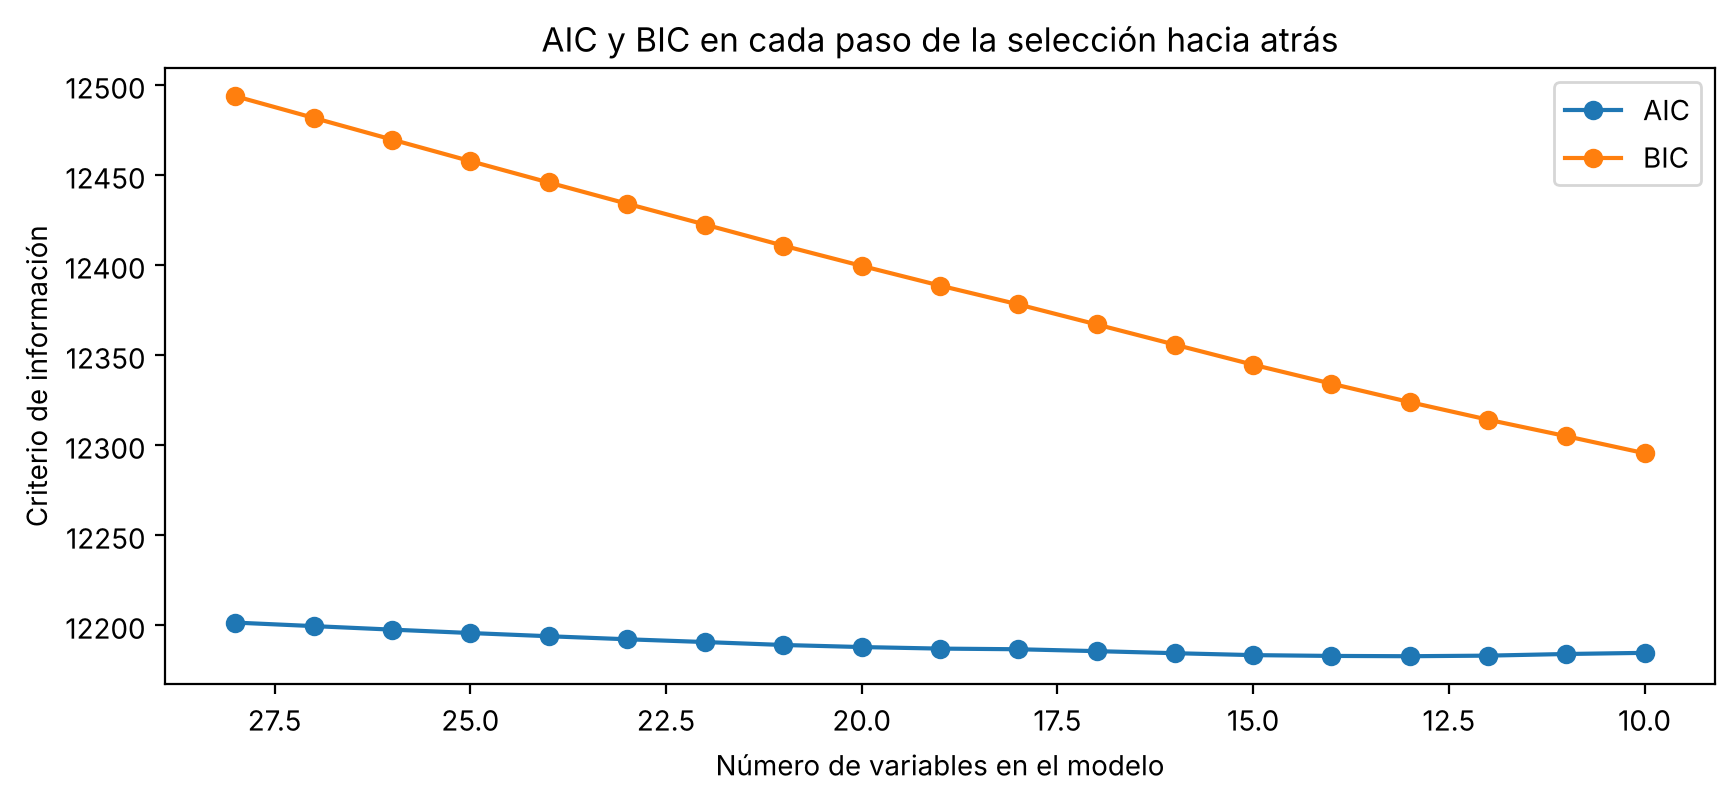

Variables finales: ['EDAD_ANOS', 'HEMORRAGICOS', 'DIABETES', 'ENFERMEDAD_RENAL', 'INMUNOSUPR', 'CIRROSIS_HEPATICA', 'HOSPITALIZADO', 'MES_ABR', 'MES_JUN', 'EDAD_ANOS_2']


In [6]:
plt.figure(figsize=(10, 4))
plt.plot(pasos['Núm. variables'], pasos['AIC'], marker='o', label='AIC')
plt.plot(pasos['Núm. variables'], pasos['BIC'], marker='o', label='BIC')
plt.gca().invert_xaxis()
plt.xlabel('Número de variables en el modelo')
plt.ylabel('Criterio de información')
plt.title('AIC y BIC en cada paso de la selección hacia atrás')
plt.legend()
plt.show()

print('Variables finales:', variables)

**Interpretación.**

- Se eliminaron **18 variables** en este orden: embarazo, 7 dummies de mes, entidad costera, sexo, los 4 serotipos, hipertensión e indígena. El modelo final tiene **10 variables**: edad, edad², hemorrágicos, diabetes, enfermedad renal, inmunosupresión, cirrosis, hospitalización y los meses de abril y junio.
- El **BIC baja en todos los pasos** (de 12,494 a 12,296): según este criterio, el modelo con 10 variables es el mejor, porque las variables eliminadas no compensan la penalización por complejidad.
- El **AIC prácticamente no cambia** (de 12,201 a 12,185) y su mínimo está en 13 variables (12,182.8); el modelo final queda solo 1.9 unidades arriba. Una diferencia menor a 2 en AIC se considera despreciable, así que **AIC y BIC coinciden en que el modelo de 10 variables es adecuado**, y es el más simple.
- **Nota sobre los meses:** al eliminar dummies de mes de forma individual, esos meses se agrupan con la referencia (octubre). Por eso `MES_ABR` y `MES_JUN` se interpretan como "iniciar síntomas en abril (o junio) comparado con **el resto de los meses**".
- Hipertensión tenía un OR crudo alto en el EDA (≈ 5), pero deja de ser significativa en el modelo: al ajustar por la edad y la diabetes, con las que está correlacionada, su efecto adicional es pequeño.

In [7]:
# ¿Se justifica el término edad²? Modelo final con y sin él
sin_edad2 = [v for v in variables if v != 'EDAD_ANOS_2']
modelo_sin_edad2 = sm.Logit(y_train, sm.add_constant(X_train[sin_edad2])).fit(disp=0)

pd.DataFrame({
    'AIC': [modelo.aic, modelo_sin_edad2.aic],
    'BIC': [modelo.bic, modelo_sin_edad2.bic],
    'Pseudo R²': [modelo.prsquared, modelo_sin_edad2.prsquared],
}, index=['Con edad²', 'Sin edad²']).round(3)

,AIC,BIC,Pseudo R²
Con edad²,12184.650,12295.531,0.173
Sin edad²,12270.836,12371.637,0.167


**Interpretación.** Al quitar edad², el AIC sube 86 unidades y el BIC 76, y el pseudo R² baja. El término cuadrático mejora claramente el modelo, lo que confirma lo observado en el EDA: la relación entre la edad y el log-odds de fallecer **no es lineal**.

## 5. Modelo final: interpretación de coeficientes y *odds ratios*

In [8]:
modelo_final = sm.Logit(y_train, sm.add_constant(X_train[variables])).fit(disp=0)
print(modelo_final.summary())

                           Logit Regression Results                           
Dep. Variable:              DEFUNCION   No. Observations:               176330
Model:                          Logit   Df Residuals:                   176319
Method:                           MLE   Df Model:                           10
Date:                Sat, 21 Nov 2026   Pseudo R-squ.:                  0.1729
Time:                        13:24:12   Log-Likelihood:                -6081.3
converged:                       True   LL-Null:                       -7352.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -7.7462      0.161    -48.057      0.000      -8.062      -7.430
EDAD_ANOS            -0.0204      0.005     -4.275      0.000      -0.030      -0.011
HEMORRAGICOS          0.

In [9]:
# Odds ratio = e^beta, con su intervalo de confianza al 95 %
ic = np.exp(modelo_final.conf_int())
odds_ratios = pd.DataFrame({
    'Coeficiente (β)': modelo_final.params,
    'Odds ratio (e^β)': np.exp(modelo_final.params),
    'IC 95% inferior': ic[0],
    'IC 95% superior': ic[1],
    'p-value': modelo_final.pvalues,
}).drop(index='const').sort_values('Odds ratio (e^β)', ascending=False)
odds_ratios.round(4)

,Coeficiente (β),Odds ratio (e^β),IC 95% inferior,IC 95% superior,p-value
HOSPITALIZADO,3.4475,31.4221,23.8927,41.3242,0.0000
ENFERMEDAD_RENAL,1.4355,4.2019,3.0415,5.8050,0.0000
CIRROSIS_HEPATICA,1.1758,3.2406,1.5146,6.9335,0.0024
INMUNOSUPR,0.7292,2.0733,1.0875,3.9527,0.0268
HEMORRAGICOS,0.6413,1.8989,1.4291,2.5232,0.0000
DIABETES,0.5336,1.7051,1.4096,2.0626,0.0000
MES_ABR,0.4136,1.5122,1.0731,2.1310,0.0181
MES_JUN,0.3222,1.3802,1.0886,1.7499,0.0078
EDAD_ANOS_2,0.0005,1.0005,1.0004,1.0006,0.0000
EDAD_ANOS,-0.0204,0.9798,0.9706,0.9890,0.0000


**Interpretación de los *odds ratios*** (manteniendo constantes las demás variables):

| Variable | OR | Interpretación |
|---|---|---|
| Hospitalizado | 31.4 | Los odds de fallecer de un paciente hospitalizado son **31 veces** los de un paciente ambulatorio |
| Enfermedad renal | 4.2 | Tener enfermedad renal multiplica los odds de fallecer por 4.2 |
| Cirrosis hepática | 3.2 | Multiplica los odds por 3.2 (intervalo amplio, 1.5–6.9, porque hay pocos casos) |
| Inmunosupresión | 2.1 | Multiplica los odds por 2.1 (intervalo amplio, 1.1–4.0) |
| Hemorrágicos | 1.9 | Multiplica los odds por 1.9 |
| Diabetes | 1.7 | Multiplica los odds por 1.7 |
| Abril / junio | 1.5 / 1.4 | Iniciar síntomas en esos meses aumenta los odds entre 40 y 50 % frente al resto del año |

Todas las comorbilidades tienen OR mayor a 1 y ningún intervalo de confianza incluye al 1, es decir, todas **aumentan** el riesgo de forma significativa.

**Edad:** sus coeficientes no se interpretan por separado. El coeficiente lineal es negativo (−0.020) y el cuadrático positivo (0.0005), lo que forma una parábola: el riesgo baja en las primeras edades y después sube cada vez más rápido. Su efecto se muestra en la siguiente gráfica.

Ambulatorio: edad con menor riesgo = 20 años | prob. a los 0 años = 0.04 %, 20 años = 0.04 %, 60 años = 0.08 %, 85 años = 0.32 %
Hospitalizado: edad con menor riesgo = 20 años | prob. a los 0 años = 1.34 %, 20 años = 1.10 %, 60 años = 2.50 %, 85 años = 9.09 %


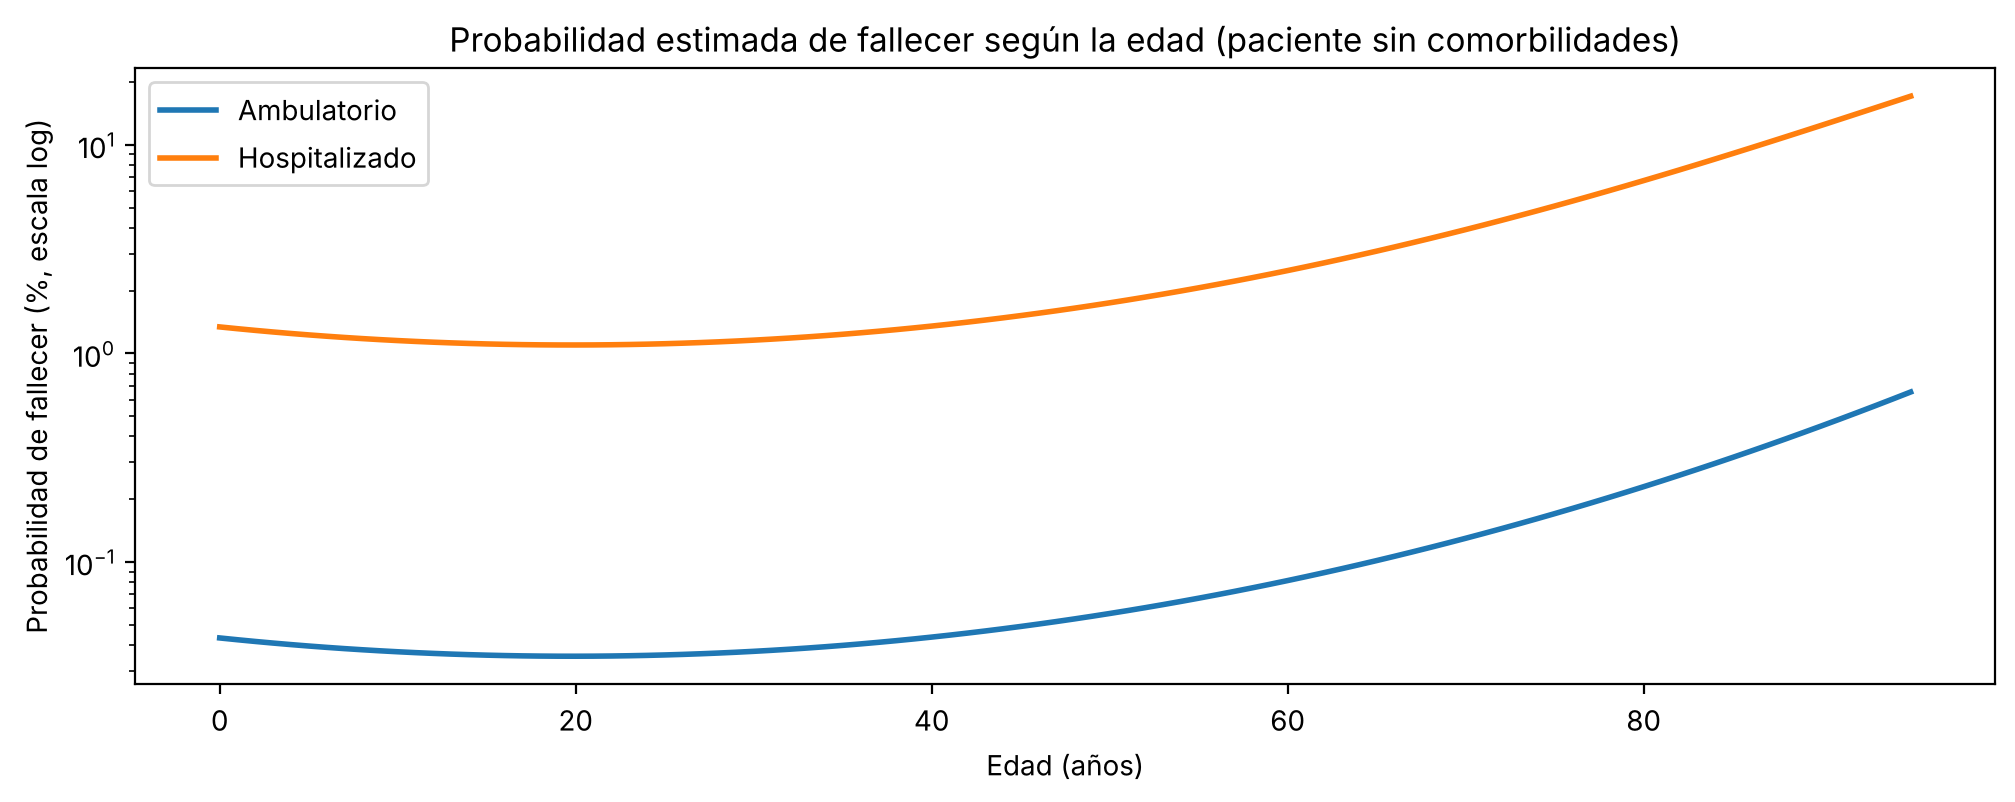

In [10]:
# Efecto de la edad: probabilidad estimada para un paciente de referencia
# (sin ninguna comorbilidad, sin hemorragia, mes distinto de abril y junio), ambulatorio y hospitalizado
edades = np.arange(0, 96)
plt.figure(figsize=(12, 4))
for hosp, etiqueta in [(0, 'Ambulatorio'), (1, 'Hospitalizado')]:
    perfil = pd.DataFrame(0, index=edades, columns=variables)
    perfil['EDAD_ANOS'] = edades
    perfil['EDAD_ANOS_2'] = edades ** 2
    perfil['HOSPITALIZADO'] = hosp
    prob = modelo_final.predict(sm.add_constant(perfil, has_constant='add'))
    plt.plot(edades, prob * 100, lw=2, label=etiqueta)
    print(f'{etiqueta}: edad con menor riesgo = {edades[np.argmin(prob)]} años | '
          f'prob. a los 0 años = {prob[0]*100:.2f} %, 20 años = {prob[20]*100:.2f} %, '
          f'60 años = {prob[60]*100:.2f} %, 85 años = {prob[85]*100:.2f} %')
plt.yscale('log')
plt.xlabel('Edad (años)')
plt.ylabel('Probabilidad de fallecer (%, escala log)')
plt.title('Probabilidad estimada de fallecer según la edad (paciente sin comorbilidades)')
plt.legend()
plt.show()

**Interpretación.** Para un paciente sin comorbilidades, el riesgo es mínimo alrededor de los **20 años** y aumenta en ambos extremos, como se observó en el EDA. Para un paciente **hospitalizado**, la probabilidad de fallecer pasa de 1.1 % a los 20 años a 2.5 % a los 60 y a **9.1 % a los 85**. En pacientes **ambulatorios** el riesgo es mucho menor en todas las edades (0.04 % a los 20 años y 0.32 % a los 85).

## 6. Análisis de la variable `HOSPITALIZADO`

Uno de los supuestos de la regresión logística es que las variables independientes **no deben ser afectadas por la variable dependiente** (endogeneidad). La hospitalización no es causada por la muerte, pero sí es una **consecuencia de la gravedad** del paciente: los pacientes más graves se hospitalizan y también tienen mayor riesgo de morir. Por eso se compara el modelo final con el mismo modelo **sin** `HOSPITALIZADO`.

In [11]:
sin_hosp = [v for v in variables if v != 'HOSPITALIZADO']
modelo_sin_hosp = sm.Logit(y_train, sm.add_constant(X_train[sin_hosp])).fit(disp=0)

comparacion = pd.DataFrame({
    'AIC': [modelo_final.aic, modelo_sin_hosp.aic],
    'BIC': [modelo_final.bic, modelo_sin_hosp.bic],
    'Pseudo R²': [modelo_final.prsquared, modelo_sin_hosp.prsquared],
    'ROC-AUC (prueba)': [roc_auc_score(y_test, modelo_final.predict(sm.add_constant(X_test[variables]))),
                         roc_auc_score(y_test, modelo_sin_hosp.predict(sm.add_constant(X_test[sin_hosp])))],
}, index=['Con HOSPITALIZADO', 'Sin HOSPITALIZADO'])
print(comparacion.round(3))

# Odds ratios de las demás variables en ambos modelos
pd.DataFrame({
    'OR con HOSPITALIZADO': np.exp(modelo_final.params),
    'OR sin HOSPITALIZADO': np.exp(modelo_sin_hosp.params),
}).drop(index=['const', 'EDAD_ANOS', 'EDAD_ANOS_2']).round(2)

                         AIC        BIC  Pseudo R²  ROC-AUC (prueba)
Con HOSPITALIZADO  12184.650  12295.531      0.173             0.863
Sin HOSPITALIZADO  13813.136  13913.937      0.062             0.679


,OR con HOSPITALIZADO,OR sin HOSPITALIZADO
CIRROSIS_HEPATICA,3.24,4.62
DIABETES,1.71,2.50
ENFERMEDAD_RENAL,4.20,6.63
HEMORRAGICOS,1.90,2.13
HOSPITALIZADO,31.42,NaN
INMUNOSUPR,2.07,2.69
MES_ABR,1.51,1.60
MES_JUN,1.38,1.24


**Interpretación.**

- **Sin `HOSPITALIZADO` el modelo empeora mucho:** el AIC sube de 12,185 a 13,813, el pseudo R² baja de 0.173 a 0.062 y el ROC-AUC en prueba cae de 0.86 a 0.68. La hospitalización concentra la mayor parte de la capacidad predictiva.
- **Las comorbilidades aumentan su OR cuando se quita la hospitalización** (por ejemplo, enfermedad renal pasa de 4.2 a 6.6 y diabetes de 1.7 a 2.5). Esto indica que parte del efecto de las comorbilidades ocurre *a través* de la hospitalización: los pacientes con comorbilidades se agravan, se hospitalizan y por eso mueren más.
- **Decisión:** se conserva `HOSPITALIZADO` en el modelo final porque mejora claramente el ajuste y la predicción, y porque la variable se conoce desde la primera atención del paciente (no depende del desenlace). Sin embargo, sus coeficientes deben leerse como **efecto adicional a la hospitalización**, y el OR de 31 no significa que hospitalizar "cause" la muerte: refleja que se hospitaliza a los pacientes más graves.

## 7. Separabilidad de las probabilidades estimadas

Un modelo de regresión logística bien ajustado debería asignar probabilidades **bajas** a los sobrevivientes y **altas** a los fallecidos, de modo que las dos distribuciones queden separadas. Como las probabilidades son muy pequeñas, el eje horizontal se muestra en escala logarítmica y cada curva se normaliza por separado (`common_norm=False`) para poder compararlas a pesar del desbalance.

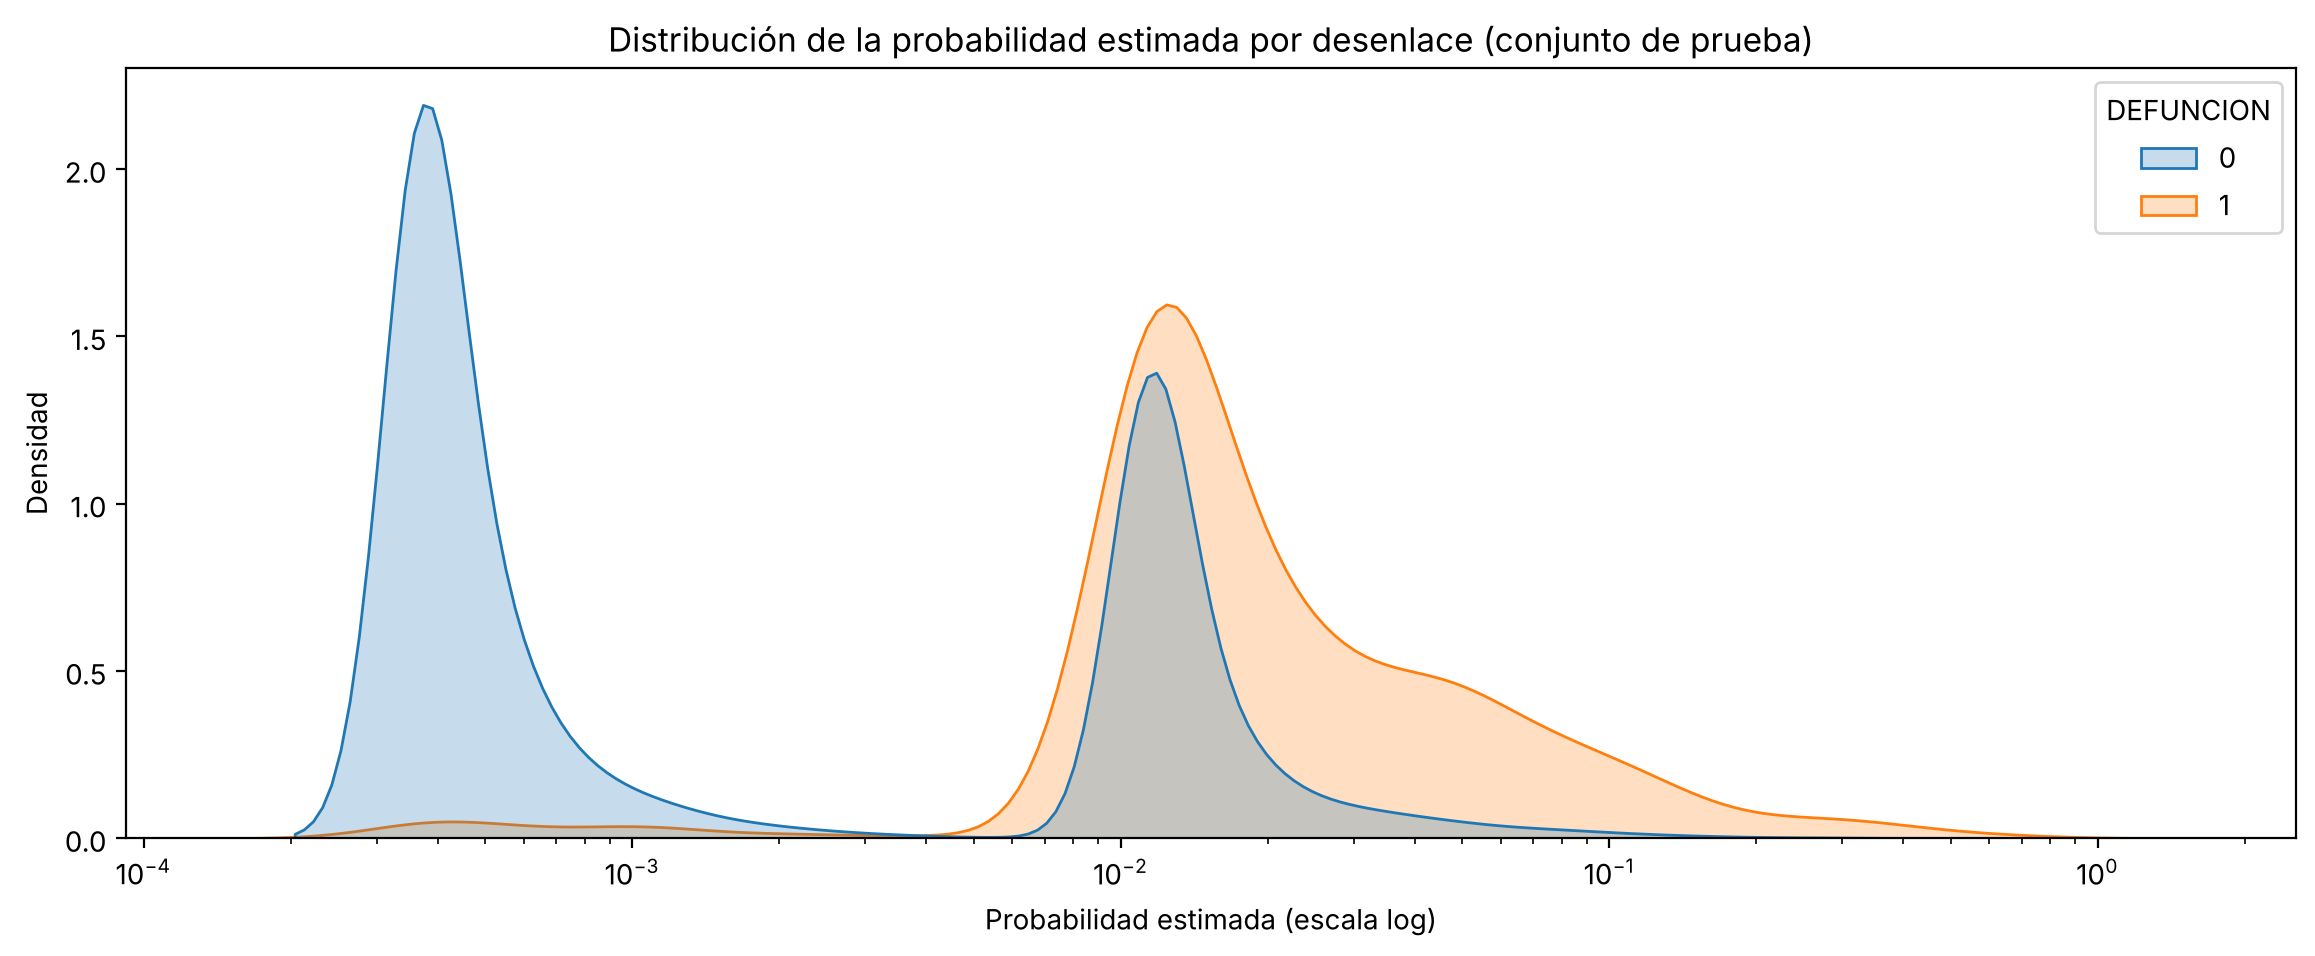

,mean,25%,50%,75%
Sobrevivió (0),0.0068,0.0004,0.0005,0.0113
Falleció (1),0.0350,0.0114,0.0148,0.0362


In [12]:
# Probabilidades estimadas en entrenamiento y prueba
prob_train = modelo_final.predict(sm.add_constant(X_train[variables]))
prob_test = modelo_final.predict(sm.add_constant(X_test[variables]))

def distribution_prob(y_real, probs, titulo):
    datos = pd.DataFrame({'DEFUNCION': y_real.values, 'predicted_probs': probs.values})
    plt.figure(figsize=(14, 5))
    sns.kdeplot(data=datos, x='predicted_probs', hue='DEFUNCION', fill=True, common_norm=False, log_scale=True)
    plt.xlabel('Probabilidad estimada (escala log)')
    plt.ylabel('Densidad')
    plt.title(titulo)
    plt.show()

distribution_prob(y_test, prob_test, 'Distribución de la probabilidad estimada por desenlace (conjunto de prueba)')

pd.DataFrame({'Sobrevivió (0)': prob_test[y_test == 0].describe(),
              'Falleció (1)': prob_test[y_test == 1].describe()}).T[['mean', '25%', '50%', '75%']].round(4)

**Interpretación.**

- La distribución de los **sobrevivientes** tiene un pico grande alrededor de 0.04 % (mediana de 0.05 %), mientras que la de los **fallecidos** se concentra entre 1 % y 4 % (mediana de 1.5 %). La probabilidad promedio de los fallecidos (3.5 %) es 5 veces la de los sobrevivientes (0.7 %).
- Las distribuciones tienen **dos grupos**: el pico de la izquierda corresponde a pacientes **ambulatorios** y el de la derecha a **hospitalizados**. Casi todos los fallecidos están en el grupo de la derecha.
- La separación **no es perfecta**: los sobrevivientes que fueron hospitalizados (un segundo pico azul alrededor de 1 %) se traslapan con los fallecidos. Dentro de los hospitalizados el modelo distingue menos, porque solo cuenta con la edad y las comorbilidades para diferenciarlos.
- Incluso para los fallecidos, las probabilidades estimadas son bajas (rara vez superan el 10 %). Esto es consistente con un evento raro: el modelo identifica pacientes con riesgo **mucho mayor que el promedio**, no pacientes con riesgo mayor a 50 %.

## 8. Métricas de desempeño

Definiciones (clase positiva = fallecido):

- **Accuracy**: proporción de predicciones correctas. Es engañosa con clases desbalanceadas.
- **Precision**: de los pacientes que el modelo marca como "fallece", qué proporción realmente falleció.
- **Recall (sensibilidad)**: de los pacientes que realmente fallecieron, qué proporción detectó el modelo.
- **F1-score**: media armónica de precision y recall.

En este problema, un **falso negativo** (no detectar a un paciente que va a morir) es mucho más costoso que un **falso positivo** (vigilar de más a un paciente que sobrevive), por lo que el **recall** de la clase 1 es la métrica más importante.

### 8.1 Umbral de 0.5

In [13]:
umbral = 0.5
for nombre, y_real, prob in [('ENTRENAMIENTO', y_train, prob_train), ('PRUEBA', y_test, prob_test)]:
    y_pred = (prob >= umbral).astype(int)
    print(f'===== {nombre} (umbral = {umbral}) =====')
    print('Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)')
    print(confusion_matrix(y_real, y_pred))
    print(classification_report(y_real, y_pred, digits=3))

===== ENTRENAMIENTO (umbral = 0.5) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[175094      2]
 [  1232      2]]
              precision    recall  f1-score   support

           0      0.993     1.000     0.996    175096
           1      0.500     0.002     0.003      1234

    accuracy                          0.993    176330
   macro avg      0.747     0.501     0.500    176330
weighted avg      0.990     0.993     0.990    176330

===== PRUEBA (umbral = 0.5) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[75038     3]
 [  528     1]]
              precision    recall  f1-score   support

           0      0.993     1.000     0.996     75041
           1      0.250     0.002     0.004       529

    accuracy                          0.993     75570
   macro avg      0.622     0.501     0.500     75570
weighted avg      0.988     0.993     0.990     75570



**Interpretación (umbral de 0.5).**

- La **accuracy es de 99.3 %** en entrenamiento y en prueba, pero es **engañosa**: es prácticamente la misma que se obtendría prediciendo que nadie fallece (99.3 % de los casos son sobrevivientes).
- El **recall de la clase 1 es de 0.2 %**: de 529 fallecidos en prueba, el modelo detecta **solo 1**. Como casi ninguna probabilidad estimada supera 0.5, el modelo clasifica a casi todos como sobrevivientes.
- La *precision* de la clase 1 (25–50 %) no es confiable porque se calcula sobre apenas 2 a 4 predicciones positivas.
- El **F1 de la clase 1 es prácticamente 0**. El *macro avg* (que promedia ambas clases con el mismo peso) muestra el problema: recall de 0.50, equivalente a no distinguir a los fallecidos.
- Las métricas de entrenamiento y prueba son casi idénticas, por lo que **no hay sobreajuste**: el problema es el umbral, no el modelo.

**Conclusión:** con clases tan desbalanceadas, el umbral de 0.5 no es adecuado. Se debe elegir otro umbral con la curva ROC.

### 8.2 Curva ROC y ROC-AUC

La **curva ROC** grafica, para todos los umbrales posibles, la tasa de verdaderos positivos (recall) contra la tasa de falsos positivos (1 − especificidad). El área bajo la curva (**ROC-AUC**) es la probabilidad de que, al tomar al azar un fallecido y un sobreviviente, el modelo le asigne mayor probabilidad al fallecido. Un valor de 0.5 equivale a adivinar al azar y 1 a una clasificación perfecta. Como regla general: 0.7–0.8 es aceptable, 0.8–0.9 es bueno y más de 0.9 es excelente.

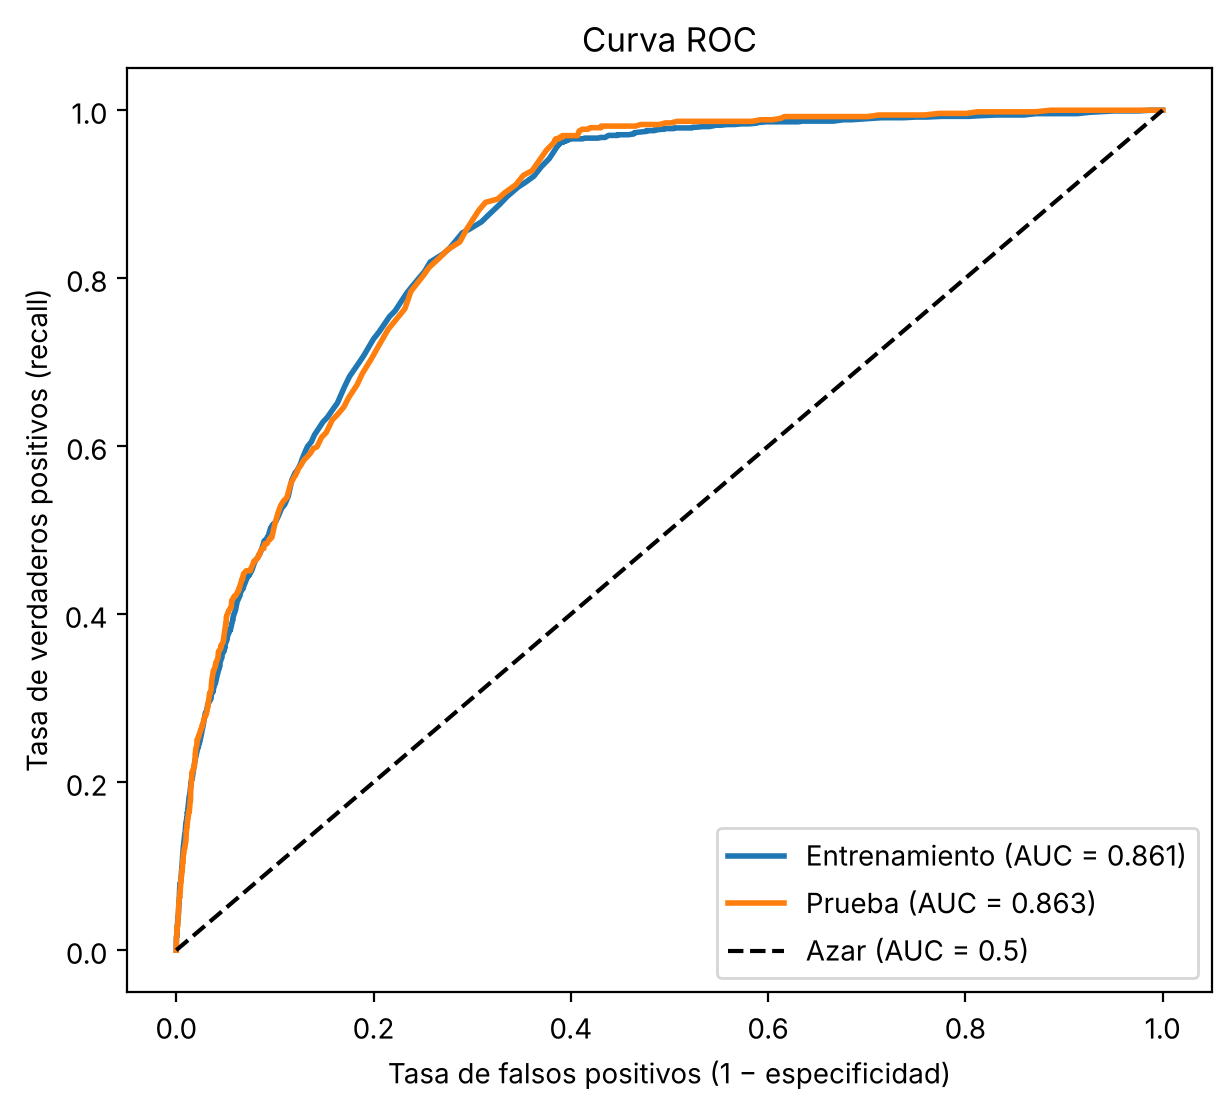

In [14]:
plt.figure(figsize=(7, 6))
for nombre, y_real, prob in [('Entrenamiento', y_train, prob_train), ('Prueba', y_test, prob_test)]:
    fpr, tpr, _ = roc_curve(y_real, prob)
    plt.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_score(y_real, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos (1 − especificidad)')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC')
plt.legend()
plt.show()

**Interpretación.**

- El **ROC-AUC es de 0.861 en entrenamiento y 0.863 en prueba**: el modelo tiene una **buena capacidad de discriminación**. Si se elige al azar un paciente que falleció y uno que sobrevivió, en el 86 % de los casos el modelo asigna mayor probabilidad al que falleció.
- A diferencia de la accuracy, el AUC **no depende del umbral ni de la proporción de clases**, por lo que es una métrica más adecuada para este problema.
- Las curvas de entrenamiento y prueba prácticamente se encimadan, lo que confirma que el modelo **generaliza bien** a datos nuevos.
- La curva sube rápido hasta un recall de ~0.96 con una tasa de falsos positivos cercana a 0.4; en ese punto se encuentra el "codo" de la curva, que corresponde a separar pacientes hospitalizados de ambulatorios.

### 8.3 Umbral elegido con la curva ROC

Se elige el umbral que **maximiza la diferencia entre la tasa de verdaderos positivos y la de falsos positivos** (índice de Youden, $TPR - FPR$), que corresponde al punto de la curva ROC más alejado de la diagonal. El umbral se calcula **solo con entrenamiento** y después se aplica a prueba.

In [15]:
fpr, tpr, umbrales = roc_curve(y_train, prob_train)
umbral_roc = umbrales[np.argmax(tpr - fpr)]
print(f'Umbral elegido: {umbral_roc:.4f}  ({umbral_roc * 100:.2f} %)\n')

for nombre, y_real, prob in [('ENTRENAMIENTO', y_train, prob_train), ('PRUEBA', y_test, prob_test)]:
    y_pred = (prob >= umbral_roc).astype(int)
    print(f'===== {nombre} (umbral = {umbral_roc:.4f}) =====')
    print('Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)')
    print(confusion_matrix(y_real, y_pred))
    print(classification_report(y_real, y_pred, digits=3))

Umbral elegido: 0.0028  (0.28 %)

===== ENTRENAMIENTO (umbral = 0.0028) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[106965  68131]
 [    47   1187]]
              precision    recall  f1-score   support

           0      1.000     0.611     0.758    175096
           1      0.017     0.962     0.034      1234

    accuracy                          0.613    176330
   macro avg      0.508     0.786     0.396    176330
weighted avg      0.993     0.613     0.753    176330

===== PRUEBA (umbral = 0.0028) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[46037 29004]
 [   18   511]]
              precision    recall  f1-score   support

           0      1.000     0.613     0.760     75041
           1      0.017     0.966     0.034       529

    accuracy                          0.616     75570
   macro avg      0.508     0.790     0.397     75570
weighted avg      0.993     0.616     0.755     75570



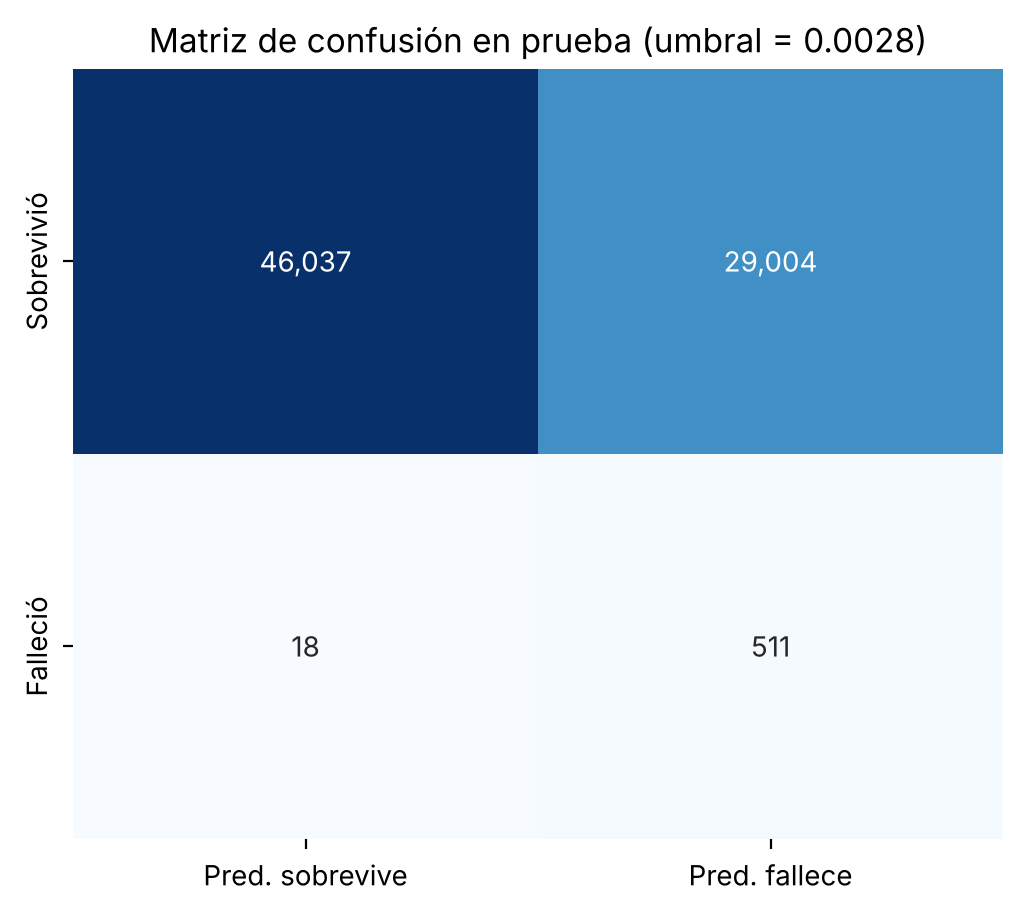

In [16]:
# Matriz de confusión del conjunto de prueba con el umbral elegido
matriz = confusion_matrix(y_test, (prob_test >= umbral_roc).astype(int))
plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Pred. sobrevive', 'Pred. fallece'], yticklabels=['Sobrevivió', 'Falleció'])
plt.title(f'Matriz de confusión en prueba (umbral = {umbral_roc:.4f})')
plt.show()

**Interpretación (umbral de 0.28 %).**

- El umbral elegido es **0.0028**: un paciente se marca como "alto riesgo" si su probabilidad estimada de fallecer es mayor a 0.28 %. Es un valor bajo, pero cercano a la tasa base de mortalidad (0.70 %), que es la escala real del problema.
- **Recall de 96.6 % en prueba:** el modelo detecta **511 de los 529 fallecidos**, y solo deja pasar 18. En entrenamiento el recall es de 96.2 %, así que el resultado es estable.
- **Precision de 1.7 %:** de cada 100 pacientes marcados como alto riesgo, menos de 2 fallecen. Esto se debe a que el modelo marca a **29,515 pacientes** (39 % del conjunto de prueba) para capturar a casi todos los fallecidos. Con un evento tan raro, una precision baja es inevitable con cualquier umbral que tenga un recall alto.
- **F1 de 0.034:** es bajo porque la precision es baja. El F1 da el mismo peso a precision y recall, pero en este contexto el recall es más importante.
- **Accuracy de 61.6 %:** baja respecto al umbral de 0.5, pero ahora el modelo sí cumple su objetivo. Esto confirma que la accuracy no es una buena métrica para este problema.
- **Valor práctico:** un paciente clasificado como "bajo riesgo" sobrevive en el 99.96 % de los casos (46,037 de 46,055). El modelo es muy útil para **descartar** riesgo y concentrar la vigilancia en el 39 % de los pacientes donde ocurren el 97 % de las muertes.

## 9. Importancia de variables con SHAP

**SHAP** (*SHapley Additive exPlanations*) reparte la predicción de cada paciente entre las variables: el valor SHAP de una variable indica cuánto **sube o baja el log-odds** de ese paciente respecto al promedio por tener el valor que tiene en esa variable. Para una regresión logística (modelo lineal en el log-odds) se usa `shap.LinearExplainer`, y el valor SHAP de la variable $j$ es $\beta_j (x_{ij} - \bar x_j)$.

- **Importancia global:** promedio del valor absoluto de SHAP de cada variable.
- **Gráfica de enjambre (*beeswarm*):** cada punto es un paciente; el color indica el valor de la variable (rojo = alto, azul = bajo) y la posición horizontal su efecto en el log-odds.

Como la edad entra con dos términos (`EDAD_ANOS` y `EDAD_ANOS_2`), sus valores SHAP se suman para obtener el efecto total de la edad.

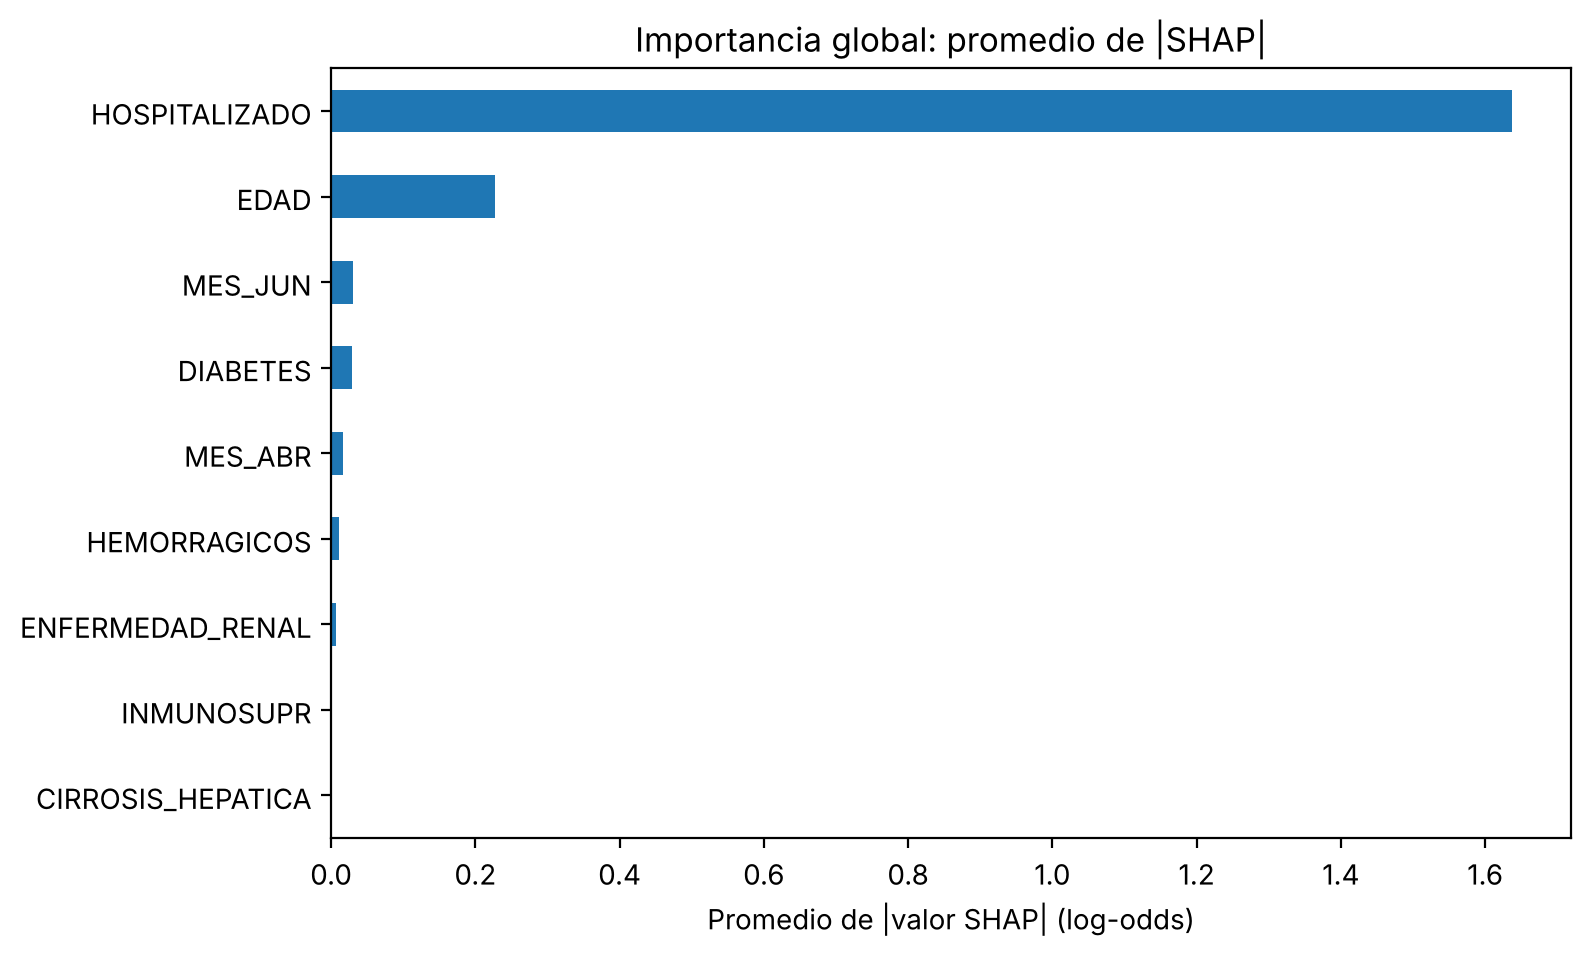

HOSPITALIZADO        1.6373
EDAD                 0.2273
MES_JUN              0.0306
DIABETES             0.0288
MES_ABR              0.0168
HEMORRAGICOS         0.0115
ENFERMEDAD_RENAL     0.0064
INMUNOSUPR           0.0018
CIRROSIS_HEPATICA    0.0015
dtype: float64

In [17]:
# Coeficientes del modelo final (sin intercepto) y datos de fondo de entrenamiento
coeficientes = modelo_final.params.drop('const').values
intercepto = modelo_final.params['const']
# El fondo (referencia) es todo el conjunto de entrenamiento: el valor SHAP se mide contra el paciente promedio
fondo = shap.maskers.Independent(X_train[variables], max_samples=len(X_train))
explainer = shap.LinearExplainer((coeficientes, intercepto), fondo)

# Valores SHAP en una muestra de 5,000 pacientes del conjunto de prueba
muestra = X_test[variables].sample(5000, random_state=42)
shap_values = pd.DataFrame(explainer.shap_values(muestra), columns=variables, index=muestra.index)

# Sumar los dos términos de la edad en una sola variable
shap_values['EDAD'] = shap_values['EDAD_ANOS'] + shap_values['EDAD_ANOS_2']
shap_values = shap_values.drop(columns=['EDAD_ANOS', 'EDAD_ANOS_2'])
valores = muestra.drop(columns=['EDAD_ANOS_2']).rename(columns={'EDAD_ANOS': 'EDAD'})[shap_values.columns]

importancia = shap_values.abs().mean().sort_values(ascending=False)
importancia.sort_values().plot.barh(figsize=(8, 5))
plt.title('Importancia global: promedio de |SHAP|')
plt.xlabel('Promedio de |valor SHAP| (log-odds)')
plt.show()
importancia.round(4)

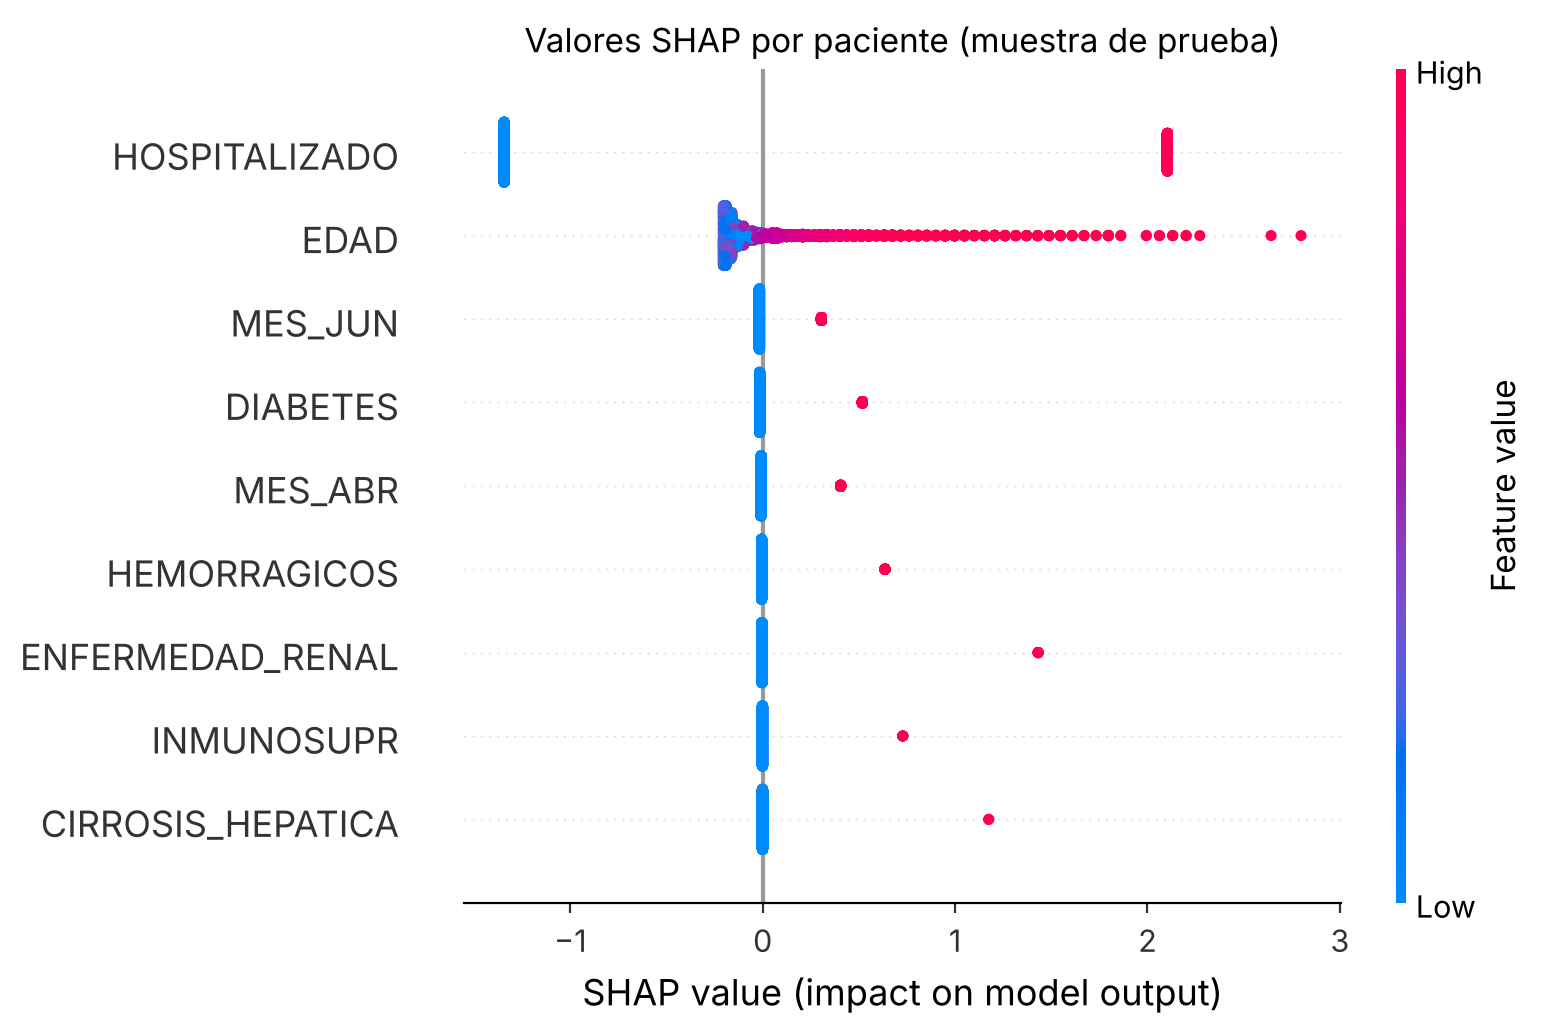

In [18]:
shap.summary_plot(shap_values.values, valores, show=False)
plt.title('Valores SHAP por paciente (muestra de prueba)')
plt.show()

**Interpretación.**

- **`HOSPITALIZADO` es, por mucho, la variable más importante** (promedio de |SHAP| = 1.64 en log-odds). En la gráfica de enjambre se ven dos grupos: los hospitalizados (rojo) aumentan su log-odds en ≈ +2.1 y los ambulatorios (azul) lo reducen en ≈ −1.3 respecto al paciente promedio.
- **La edad es la segunda variable** (0.23). Para la mayoría de los pacientes (jóvenes, en azul) su efecto es ligeramente negativo, pero para los adultos mayores (rojo) puede aumentar el log-odds en más de 2 unidades, un efecto comparable al de la hospitalización.
- **Las comorbilidades tienen un efecto individual grande pero una importancia global pequeña.** Para un paciente con enfermedad renal, el SHAP es ≈ +1.4 (el punto rojo aislado), pero como solo el 0.25 % de los pacientes la tiene, su promedio de |SHAP| es bajo. Lo mismo ocurre con cirrosis e inmunosupresión.
- **Junio y diabetes** aparecen arriba de enfermedad renal en importancia global no porque su efecto sea mayor, sino porque son **más frecuentes** (5 % y 3 % de los pacientes).

**SHAP vs. odds ratios:** los OR miden el efecto de una variable **para un paciente que la tiene**, mientras que el promedio de |SHAP| mide **cuánto contribuye la variable a las predicciones de toda la población**. Ambos coinciden en que la hospitalización domina; difieren en las comorbilidades raras, que son muy peligrosas para el paciente que las tiene, pero afectan a pocos pacientes.

## 10. Probabilidad de puntos críticos

Con base en las variables más importantes según SHAP y en las distribuciones encontradas en el EDA, se calcula la probabilidad de que un paciente se ubique en zonas de riesgo:

- **Edad:** en el EDA la mejor distribución paramétrica fue la **gamma** (aunque la prueba KS la rechaza) y la **KDE** describió mejor los datos. Se toman como puntos críticos los dos extremos de la "U": **60 años o más** (a partir de ahí la mortalidad supera el 1.5 %) y **menos de 5 años** (mortalidad de 1.17 %).
- **Hospitalización y comorbilidades:** son variables de Bernoulli, por lo que la probabilidad de que un paciente tenga la condición es su parámetro $\hat p$ estimado por MLE.

In [19]:
edad = dengue['EDAD_ANOS'].values.astype(float)
fallecidos_edad = dengue.loc[dengue['DEFUNCION'] == 1, 'EDAD_ANOS'].values

# Distribución gamma ajustada por MLE (mejor ajuste paramétrico del EDA)
params_gamma = stats.gamma.fit(edad)
# KDE de toda la población, de los fallecidos y de los sobrevivientes
kde_todos = gaussian_kde(edad, bw_method='silverman')
kde_muertos = gaussian_kde(dengue.loc[dengue['DEFUNCION'] == 1, 'EDAD_ANOS'], bw_method='silverman')
kde_vivos = gaussian_kde(dengue.loc[dengue['DEFUNCION'] == 0, 'EDAD_ANOS'], bw_method='silverman')

puntos = pd.DataFrame({
    'Gamma (MLE)': [1 - stats.gamma.cdf(60, *params_gamma), stats.gamma.cdf(5, *params_gamma)],
    'KDE (todos)': [kde_todos.integrate_box_1d(60, 150), kde_todos.integrate_box_1d(-10, 5)],
    'Empírica (todos)': [(edad >= 60).mean(), (edad < 5).mean()],
    'KDE (sobrevivientes)': [kde_vivos.integrate_box_1d(60, 150), kde_vivos.integrate_box_1d(-10, 5)],
    'KDE (fallecidos)': [kde_muertos.integrate_box_1d(60, 150), kde_muertos.integrate_box_1d(-10, 5)],
    'Empírica (fallecidos)': [(fallecidos_edad >= 60).mean(), (fallecidos_edad < 5).mean()],
}, index=['P(edad ≥ 60)', 'P(edad < 5)'])
(puntos * 100).round(2)

,Gamma (MLE),KDE (todos),Empírica (todos),KDE (sobrevivientes),KDE (fallecidos),Empírica (fallecidos)
P(edad ≥ 60),6.32,6.41,6.64,6.28,25.03,25.01
P(edad < 5),3.99,3.59,2.71,3.58,7.46,4.54


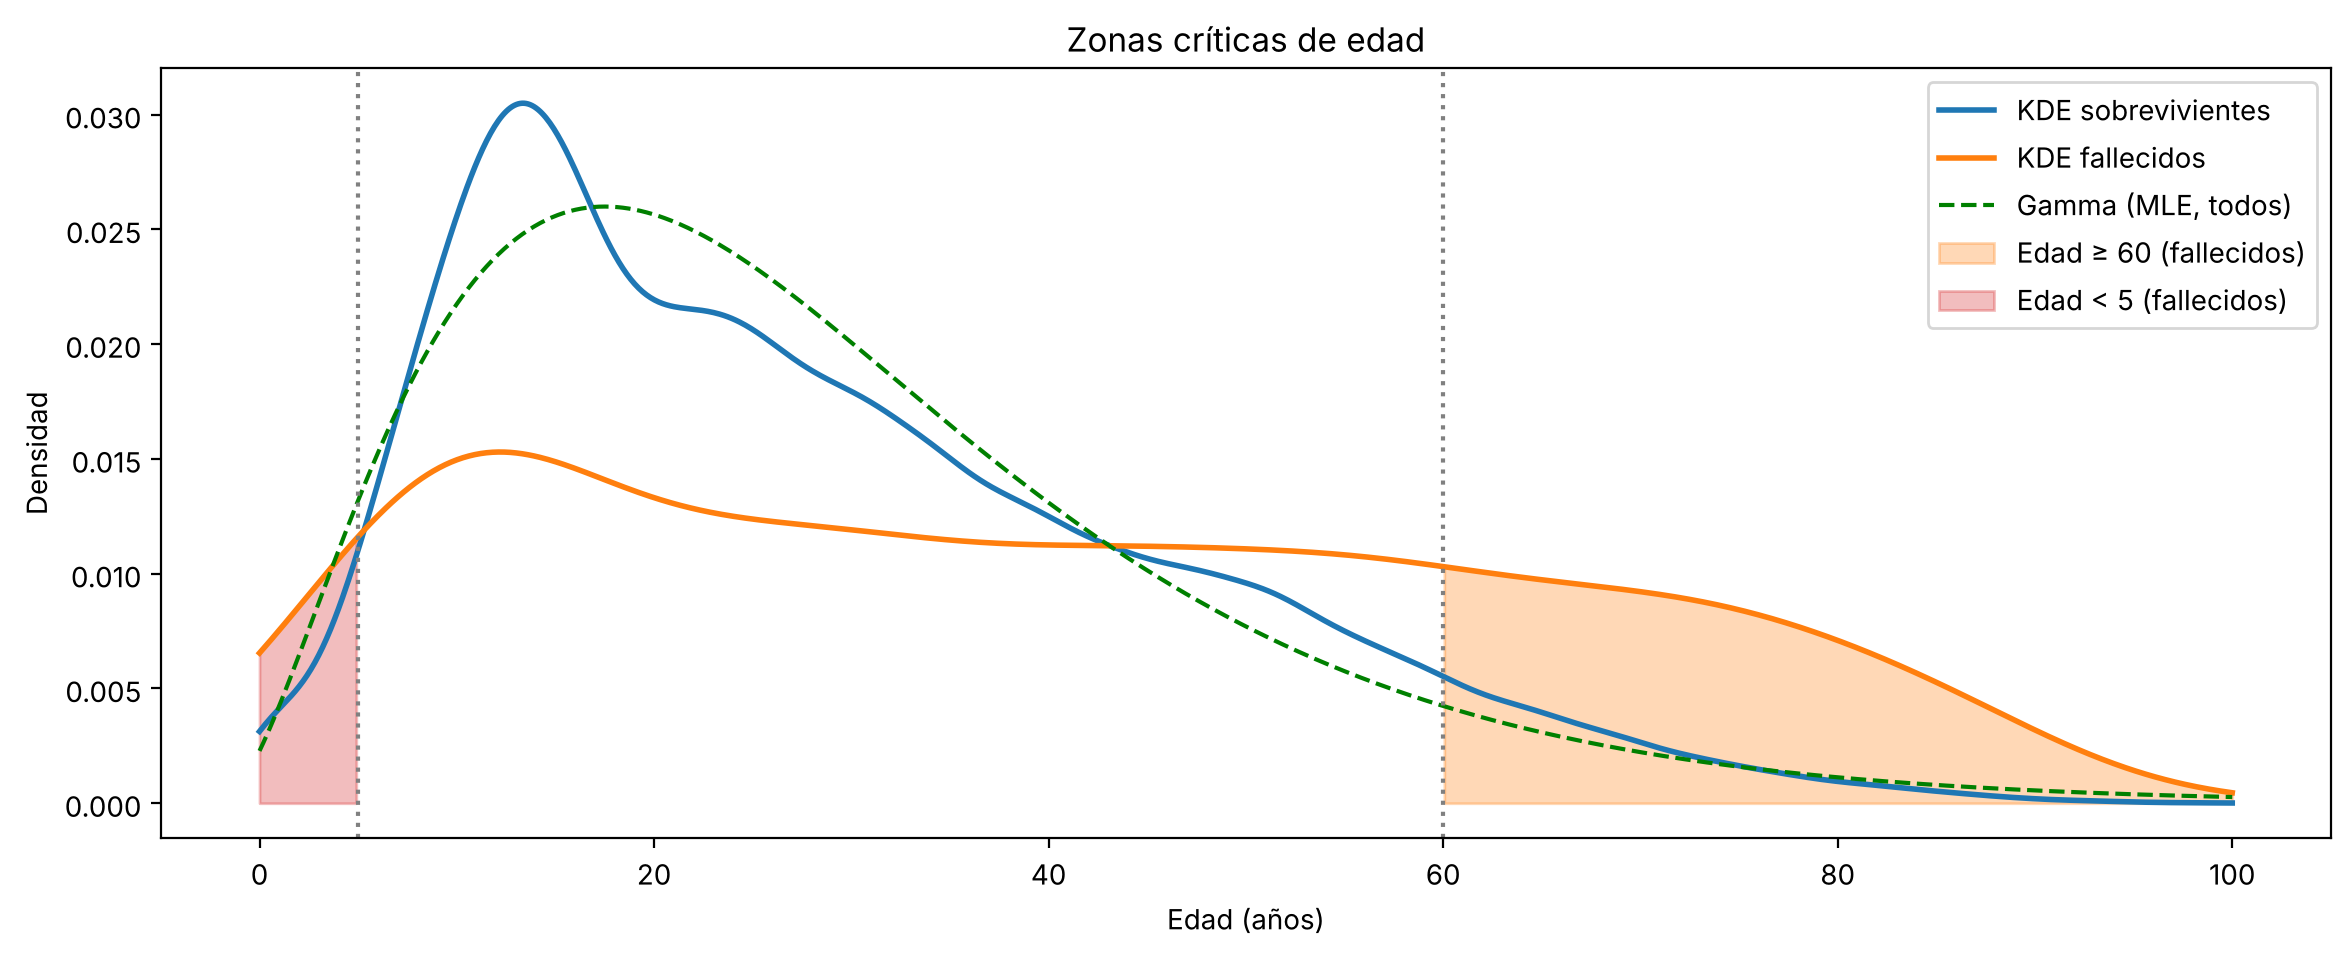

In [20]:
x = np.linspace(0, 100, 1000)
plt.figure(figsize=(14, 5))
plt.plot(x, kde_vivos(x), lw=2, label='KDE sobrevivientes')
plt.plot(x, kde_muertos(x), lw=2, label='KDE fallecidos')
plt.plot(x, stats.gamma.pdf(x, *params_gamma), 'g--', lw=1.5, label='Gamma (MLE, todos)')
plt.fill_between(x, kde_muertos(x), where=(x >= 60), alpha=0.3, color='tab:orange', label='Edad ≥ 60 (fallecidos)')
plt.fill_between(x, kde_muertos(x), where=(x < 5), alpha=0.3, color='tab:red', label='Edad < 5 (fallecidos)')
plt.axvline(60, color='gray', linestyle=':')
plt.axvline(5, color='gray', linestyle=':')
plt.xlabel('Edad (años)')
plt.ylabel('Densidad')
plt.title('Zonas críticas de edad')
plt.legend()
plt.show()

In [21]:
# Variables binarias más importantes: parámetro p de Bernoulli (MLE = proporción)
binarias_top = [v for v in importancia.index if v != 'EDAD' and not v.startswith('MES_')][:5]
pd.DataFrame({
    'P(condición) todos': dengue[binarias_top].mean(),
    'P(condición | falleció)': dengue.loc[dengue['DEFUNCION'] == 1, binarias_top].mean(),
    'P(fallecer | condición)': [dengue.loc[dengue[v] == 1, 'DEFUNCION'].mean() for v in binarias_top],
    'P(fallecer | sin condición)': [dengue.loc[dengue[v] == 0, 'DEFUNCION'].mean() for v in binarias_top],
}).mul(100).round(2)

,P(condición) todos,P(condición | falleció),P(fallecer | condición),P(fallecer | sin condición)
HOSPITALIZADO,38.91,95.80,1.72,0.05
DIABETES,2.88,14.92,3.63,0.61
HEMORRAGICOS,0.91,5.05,3.89,0.67
ENFERMEDAD_RENAL,0.25,4.37,12.16,0.67
INMUNOSUPR,0.15,0.91,4.31,0.69


**Interpretación.**

- **Edad ≥ 60 años:** la gamma y la KDE estiman que el **6.3–6.4 %** de los pacientes con dengue tiene 60 años o más (el valor empírico es 6.6 %). Sin embargo, **el 25 % de las muertes** ocurre en ese grupo (KDE y valor empírico coinciden): los adultos mayores son 1 de cada 15 pacientes, pero 1 de cada 4 muertes.
- **Edad < 5 años:** el 2.7 % de los pacientes son menores de 5 años, pero representan el **4.5 % de las muertes** (1.7 veces su peso en la población). En esta zona la gamma (4.0 %) y la KDE (3.6 % en todos, 7.5 % en fallecidos) **sobreestiman** la probabilidad, porque suavizan la densidad cerca de 0 y le asignan masa a edades negativas. Es una limitación de ambos métodos en el borde de la variable, por lo que aquí conviene usar el valor empírico.
- **Hospitalización:** la probabilidad de que un paciente sea hospitalizado es de 39 %, pero el 96 % de los fallecidos estuvo hospitalizado. La probabilidad de fallecer es de 1.72 % si se hospitaliza y de 0.05 % si no.
- **Comorbilidades:** son condiciones raras (de 0.15 % a 2.9 % de los pacientes), pero quien las tiene enfrenta una mortalidad de **3.6 % (diabetes) a 12.2 % (enfermedad renal)**, contra menos de 0.7 % sin ellas.

Estas probabilidades permiten dimensionar a la población en riesgo: los pacientes en los extremos de edad (≈ 9 % del total) concentran ≈ 30 % de las muertes.

## 11. Conclusiones

### ¿El modelo captura el comportamiento de la variable de respuesta?

Sí, de forma **buena para discriminar** y **limitada para confirmar**:

- Con un **ROC-AUC de 0.86** en prueba, el modelo ordena correctamente el riesgo de los pacientes en el 86 % de los pares fallecido–sobreviviente, y el desempeño es igual en entrenamiento y prueba (no hay sobreajuste).
- Con el umbral elegido por la curva ROC (0.28 %), detecta al **96.6 % de los fallecidos** del conjunto de prueba, aunque solo el 1.7 % de los pacientes marcados como alto riesgo fallece. El modelo es útil para **descartar riesgo** (99.96 % de los pacientes marcados como bajo riesgo sobrevive), no para predecir con certeza quién morirá.
- El **pseudo R² de 0.17** indica que una parte importante de la variación no se explica con las variables disponibles.
- El umbral de 0.5 **no sirve** para este problema: da una accuracy de 99.3 % pero detecta solo 1 de 529 fallecidos.

### Importancia de las variables y hallazgos del EDA

1. **Hospitalización:** la variable más importante (OR = 31; principal variable según SHAP). El 96 % de los fallecidos estuvo hospitalizado. Refleja la gravedad del paciente; sin ella, el AUC cae a 0.68.
2. **Edad:** segunda en importancia. La mortalidad tiene forma de "U" (mínima alrededor de los 20 años, alta en menores de 5 y muy alta en adultos mayores), por lo que fue necesario incluir **edad²**. Los mayores de 60 años son el 6.6 % de los pacientes pero el 25 % de las muertes.
3. **Comorbilidades:** enfermedad renal (OR = 4.2), cirrosis (3.2), inmunosupresión (2.1), hemorrágicos (1.9) y diabetes (1.7) aumentan significativamente el riesgo. Son raras en la población, por lo que su importancia global es baja, pero son críticas a nivel individual.
4. **Variables sin efecto:** sexo, embarazo, condición indígena, entidad costera y serotipo no son significativas al ajustar por las demás variables. La hipertensión era importante en el EDA, pero deja de ser significativa al ajustar por la edad y la diabetes, con las que está correlacionada.
5. **Estacionalidad:** los casos se concentran en agosto–noviembre, pero la mortalidad es algo mayor en abril y junio (fuera de temporada alta), posiblemente porque en temporada alta se confirman más casos leves.

### Recomendaciones y mejoras futuras

- **Uso del modelo:** como herramienta de **tamizaje**, para priorizar la vigilancia de pacientes hospitalizados, mayores de 60 años, menores de 5 años o con enfermedad renal, cirrosis, inmunosupresión, diabetes o manifestaciones hemorrágicas.
- **Agregar variables clínicas:** los datos no incluyen signos de alarma, resultados de laboratorio (plaquetas, hematocrito) ni días transcurridos desde el inicio de síntomas, que probablemente explican buena parte de la mortalidad no capturada (pseudo R² de 0.17).
- **Separar el análisis por tipo de paciente:** ajustar un modelo solo con pacientes hospitalizados permitiría distinguir mejor el riesgo dentro del grupo donde ocurren casi todas las muertes.
- **Manejo del desbalance:** probar técnicas de sobremuestreo o submuestreo y comparar con el ajuste del umbral.
- **Calidad de los datos:** los datos son de vigilancia epidemiológica y puede haber subregistro de comorbilidades; además, una asociación en el modelo no implica causalidad.

### Insights principales

- **1 de cada 142** pacientes con dengue confirmado fallece, pero el riesgo está muy concentrado: el 39 % de los pacientes (marcados como alto riesgo) concentra el 97 % de las muertes.
- Un paciente **hospitalizado de 85 años** sin comorbilidades tiene una probabilidad estimada de fallecer de **9.1 %**, contra **1.1 %** a los 20 años.
- La **enfermedad renal** es la comorbilidad más peligrosa: 12 % de mortalidad en quienes la tienen, 18 veces la de quienes no.